In [45]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

In [46]:
df=pd.read_csv(r'C:\Users\hp\Desktop\5thsem_ojt\project1_diabetes\data\processed\aman_p1w2_features.csv')

In [47]:
df.head()

,patient_id,age,gender,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,...,smoker,last_checkup_date,outcome,age_band,bmi_category,glucose_band,insulin_glucose_ratio,prgnencies_age_rate,days_since_checkup,activity_smoker
0,P00826,79,male,0,124.0,71.0,30.0,124.0,23.4,0.588,...,NO,2023-04-20,0,senior,normal,prediabetic,1.000000,0.000000,618,Unknown/NO
1,P00108,37,male,0,153.0,85.0,24.0,42.0,33.9,0.192,...,YES,2024-05-03,1,middle-aged,obese,diabetic,0.274510,0.000000,239,Medium/YES
2,P00517,39,female,0,142.0,68.0,22.0,159.0,26.9,0.777,...,UNKNOWN,2023-07-08,0,middle-aged,overweight,diabetic,1.119718,0.000000,539,Low/UNKNOWN
3,P00687,68,female,7,121.0,88.0,26.0,124.0,29.0,1.217,...,YES,2024-04-14,1,senior,overweight,prediabetic,1.024793,0.102941,258,Unknown/YES
4,P00927,75,female,0,107.0,84.0,31.0,101.0,21.2,0.278,...,NO,2024-01-27,0,senior,normal,prediabetic,0.943925,0.000000,336,Low/NO


In [48]:
feature_cols=['age','pregnancies','glucose','blood_pressure','skin_thickness','insulin','bmi','diabetes_pedigree','bmi_category','glucose_band']



In [49]:
x=df[feature_cols]
y=df['outcome']

In [50]:
                                                               
x=pd.get_dummies(x,drop_first=True)

In [51]:
x_train,x_test,y_train,y_test= train_test_split(
x,y,test_size=0.2,random_state=42,stratify=y)

In [52]:
scaler = StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [53]:
logreg = LogisticRegression(max_iter=1000).fit(x_train_scaled, y_train)
dec_tree=DecisionTreeClassifier(max_depth=3).fit(x_train,y_train)
knn_best = KNeighborsClassifier(n_neighbors=25).fit(x_train_scaled, y_train)

In [54]:
print('LogisticRegression',accuracy_score(y_test,logreg.predict(x_test_scaled)))
print('DecisionTreeClassifier',accuracy_score(y_test,dec_tree.predict(x_test)))
print('kneighborsclassifier',accuracy_score(y_test,knn_best.predict(x_test_scaled)))

LogisticRegression 0.7526315789473684
DecisionTreeClassifier 0.7210526315789474
kneighborsclassifier 0.7473684210526316


In [55]:
print('test set:',len(y_test),'patients |',int(np.sum(y_test)),'of them diabetic')

test set: 190 patients | 55 of them diabetic


In [56]:
models=[('logisticregression',logreg,x_test_scaled),
        ('DecisionTreeClassifier(d=3)',dec_tree,x_test),
        ('knn(k=25)',knn_best,x_test_scaled)]

In [57]:
rows=[]
for name,m,xt in models:
    cm=confusion_matrix(y_test,m.predict(xt))
    tn,fp,fn,tp=cm.ravel()
    rows.append({"model":name,"correct_negatives":int(tn),"false_alarams":int(fp),
              "missed_patients":int(fn),"found_patients":int(tp),
              "accuracy": round(accuracy_score(y_test,m.predict(xt)),4)})
matrix=pd.DataFrame(rows)
matrix


,model,correct_negatives,false_alarams,missed_patients,found_patients,accuracy
0,logisticregression,127,8,39,16,0.7526
1,DecisionTreeClassifier(d=3),121,14,39,16,0.7211
2,knn(k=25),132,3,45,10,0.7474


                        logistic regression
* **127 (TN):** 127 people were correctly identified as not having diabetes.
* **8 (FP):** 8 people were incorrectly identified as having diabetes.
* **39 (FN):** 39 people who actually had diabetes were missed by the model.
* **16 (TP):** 16 people who had diabetes were correctly identified by the model.


* **Logistic Regression:** The main error is **missed patients (FN = 39)**.
* **Decision Tree:** The main error is **missed patients (FN = 39)**, along with 14 false alarms.
* **KNN:** The main error is **missed patients (FN = 45)**, which is the highest among the three models.



score the model that never says yes

In [58]:
from sklearn.dummy import DummyClassifier


In [59]:
dummy=DummyClassifier(strategy='most_frequent')
dummy.fit(x_train,y_train)
y_pred=dummy.predict(x_test)
confusion_matrix(y_test,y_pred)

array([[135,   0],
       [ 55,   0]])

In [60]:
print('dummyclassifier',accuracy_score(y_test,y_pred))

dummyclassifier 0.7105263157894737


In [61]:
y_test.value_counts(normalize=True)

outcome
0    0.710526
1    0.289474
Name: proportion, dtype: float64

# precision and recall

In [62]:
# Recall tells us how many of the actual positive cases the model correctly found.
# tp/tp+fn


In [63]:
cm=confusion_matrix(y_test,logreg.predict(x_test_scaled))
tn,fp,fn,tp=cm.ravel()
print('recall:tp/tp+fn=',tp/(tp+fn))

recall:tp/tp+fn= 0.2909090909090909


In [64]:
from sklearn.metrics import recall_score

In [65]:
print('LogisticRegression Recall=',recall_score(y_test,logreg.predict(x_test_scaled)))


LogisticRegression Recall= 0.2909090909090909


In [66]:
print('DecisionTreeClassifier Recall=',recall_score(y_test,dec_tree.predict(x_test)))

DecisionTreeClassifier Recall= 0.2909090909090909


In [67]:
print('knn Recall=',recall_score(y_test,knn_best.predict(x_test_scaled)))


knn Recall= 0.18181818181818182


precision

In [68]:
cm=confusion_matrix(y_test,logreg.predict(x_test_scaled))
tn,fp,fn,tp=cm.ravel()
print('precision:tp/tp+fn=',tp/(tp+fp))

precision:tp/tp+fn= 0.6666666666666666


In [69]:
# Precision tells us how many of the predicted positive cases are actually positive.
# tp/tp+fn

In [70]:
from sklearn.metrics import precision_score

In [71]:
print('LogisticRegression precision=',precision_score(y_test,logreg.predict(x_test_scaled)))


LogisticRegression precision= 0.6666666666666666


In [72]:
print('DecisionTreeClassifier precision=',precision_score(y_test,dec_tree.predict(x_test)))

DecisionTreeClassifier precision= 0.5333333333333333


In [73]:
print('knn precision=',precision_score(y_test,knn_best.predict(x_test_scaled)))

knn precision= 0.7692307692307693


In [74]:
rows=[]
for name,m,xt in models:
    pred = m.predict(xt)
    cm=confusion_matrix(y_test,pred)
    tn,fp,fn,tp=cm.ravel()
    rows.append({
              "model":name,
              "recall":round(recall_score(y_test,pred,zero_division=0),4),
              "precision":round(precision_score(y_test,pred,zero_division=0),4),
              "accuracy":round(accuracy_score(y_test,pred),4),
              "correct_negatives":int(tn),"false_alarams":int(fp),
              "missed_patients":int(fn),"found_patients":int(tp)})

results=pd.DataFrame(rows)


prescion sorted

In [75]:
results.sort_values('precision', ascending=False)

,model,recall,precision,accuracy,correct_negatives,false_alarams,missed_patients,found_patients
2,knn(k=25),0.1818,0.7692,0.7474,132,3,45,10
0,logisticregression,0.2909,0.6667,0.7526,127,8,39,16
1,DecisionTreeClassifier(d=3),0.2909,0.5333,0.7211,121,14,39,16


recall sorted

In [76]:
results.sort_values('recall',ascending=False)

,model,recall,precision,accuracy,correct_negatives,false_alarams,missed_patients,found_patients
0,logisticregression,0.2909,0.6667,0.7526,127,8,39,16
1,DecisionTreeClassifier(d=3),0.2909,0.5333,0.7211,121,14,39,16
2,knn(k=25),0.1818,0.7692,0.7474,132,3,45,10


In [77]:
probs=logreg.predict_proba(x_test_scaled)[:,1]
preds=logreg.predict(x_test_scaled)
pd.DataFrame({"probability":probs[:10].round(3),
              "prediction":pred[:10],
              "actual": np.asarray(y_test)[:10]

})

,probability,prediction,actual
0,0.289,0,0
1,0.031,0,0
2,0.182,0,0
3,0.182,0,0
4,0.177,0,1
5,0.161,0,0
6,0.419,0,0
7,0.473,1,1
8,0.286,0,0
9,0.121,0,0


In [78]:
sweep=[]
for t in[0.5,0.45,0.4,0.35,0.3,0.25,0.2,0.15]:
    pred_t=(probs>=t).astype(int)
    cm=confusion_matrix(y_test,pred_t)
    tn,fp,fn,tp=cm.ravel()
    sweep.append({
              "threshold":t,
              "recall":round(recall_score(y_test,pred_t,zero_division=0),4),
              "precision":round(precision_score(y_test,pred_t,zero_division=0),4),
              "accuracy":round(accuracy_score(y_test,pred_t),4),
              "correct_negatives":int(tn),"false_alarams":int(fp),
              "missed_patients":int(fn),"found_patients":int(tp)})

sweep = pd.DataFrame(sweep)


In [79]:
sweep

,threshold,recall,precision,accuracy,correct_negatives,false_alarams,missed_patients,found_patients
0,0.50,0.2909,0.6667,0.7526,127,8,39,16
1,0.45,0.3636,0.5556,0.7316,119,16,35,20
2,0.40,0.4364,0.5000,0.7105,111,24,31,24
3,0.35,0.5636,0.5082,0.7158,105,30,24,31
4,0.30,0.6182,0.4789,0.6947,98,37,21,34
5,0.25,0.6909,0.4043,0.6158,79,56,17,38
6,0.20,0.7818,0.3874,0.5789,67,68,12,43
7,0.15,0.8727,0.3692,0.5316,53,82,7,48


# f1 score

F1 Score is a metric that combines Precision and Recall into a single score.
It is useful when we want a balance between correct positive predictions and finding actual positive cases.
equation:F1=2×
Precision+Recall/
Precision×Recall
	​

	​


In [80]:
from sklearn.metrics import f1_score

In [81]:
print('LogisticRegression f1_score=',f1_score(y_test,logreg.predict(x_test_scaled)))
print('DecisionTreeClassifier f1_score=',f1_score(y_test,dec_tree.predict(x_test)))
print('knn f1_score=',f1_score(y_test,knn_best.predict(x_test_scaled)))



LogisticRegression f1_score= 0.4050632911392405
DecisionTreeClassifier f1_score= 0.3764705882352941
knn f1_score= 0.29411764705882354


In [82]:
from sklearn.metrics import f1_score,classification_report

In [83]:
f1_score(y_test,pred)
print(classification_report(y_test,pred,digits=4))

              precision    recall  f1-score   support

           0     0.7458    0.9778    0.8462       135
           1     0.7692    0.1818    0.2941        55

    accuracy                         0.7474       190
   macro avg     0.7575    0.5798    0.5701       190
weighted avg     0.7526    0.7474    0.6864       190



In [84]:
results["f1"]=[f1_score(y_test,m.predict(Xt))
              for model,m,Xt in models]
print(
    results[["model", "accuracy", "precision", "recall", "f1"]]
    .sort_values(by="f1", ascending=False)
    .round(4)
)
print("Dummy Accuracy:", accuracy_score(y_test, y_pred))
print("Dummy Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Dummy Recall:", recall_score(y_test, y_pred, zero_division=0))
print("Dummy F1:", f1_score(y_test, y_pred, zero_division=0))

                         model  accuracy  precision  recall      f1
0           logisticregression    0.7526     0.6667  0.2909  0.4051
1  DecisionTreeClassifier(d=3)    0.7211     0.5333  0.2909  0.3765
2                    knn(k=25)    0.7474     0.7692  0.1818  0.2941
Dummy Accuracy: 0.7105263157894737
Dummy Precision: 0.0
Dummy Recall: 0.0
Dummy F1: 0.0


In [85]:
sweep['f1'] = [f1_score(y_test, (probs >= t).astype(int), zero_division=0)
               for t in sweep['threshold']]
print(sweep[['threshold', 'accuracy', 'precision', 'recall', 'f1','found_patients','missed_patients']]
      .sort_values("f1", ascending=False) .to_string(index=False))

 threshold  accuracy  precision  recall       f1  found_patients  missed_patients
      0.30    0.6947     0.4789  0.6182 0.539683              34               21
      0.35    0.7158     0.5082  0.5636 0.534483              31               24
      0.15    0.5316     0.3692  0.8727 0.518919              48                7
      0.20    0.5789     0.3874  0.7818 0.518072              43               12
      0.25    0.6158     0.4043  0.6909 0.510067              38               17
      0.40    0.7105     0.5000  0.4364 0.466019              24               31
      0.45    0.7316     0.5556  0.3636 0.439560              20               35
      0.50    0.7526     0.6667  0.2909 0.405063              16               39


compare the tuned model with the untuned one

In [86]:
tuned_pred = (probs >= 0.30).astype(int)

def score_row(label, pred):
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()

    return {
        "model": label,
        "accuracy": round(accuracy_score(y_test, pred), 4),
        "precision": round(precision_score(y_test, pred, zero_division=0), 4),
        "recall": round(recall_score(y_test, pred, zero_division=0), 4),
        "f1": round(f1_score(y_test, pred, zero_division=0), 4),
        "found": int(tp),
        "missed": int(fn),
        "false_alarms": int(fp)
    }

pd.DataFrame([
    score_row("Logistic Regression (threshold 0.50)", preds),
    score_row("Logistic Regression (threshold 0.30)", tuned_pred)
])

,model,accuracy,precision,recall,f1,found,missed,false_alarms
0,Logistic Regression (threshold 0.50),0.7526,0.6667,0.2909,0.4051,16,39,8
1,Logistic Regression (threshold 0.30),0.6947,0.4789,0.6182,0.5397,34,21,37


# The descion in one descion

we will judge this model on how many patients with diabetes it finds,because for this clinic sending diabetic patient home untested is a worse outcome than calling a healthy patient back for a test they did not need

# ROC

ROC Curve shows how well a classification model separates positive and negative classes at different thresholds.
It compares True Positive Rate (Recall) with False Positive Rate.
A curve closer to the top-left corner generally indicates better class separation.

In [88]:
from sklearn.metrics import roc_curve,roc_auc_score
import matplotlib.pyplot as plt

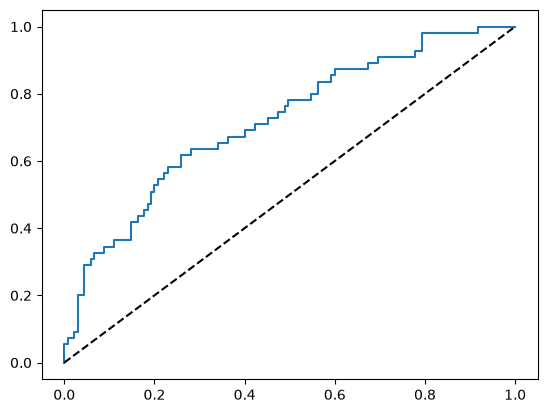

In [89]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

probs = logreg.predict_proba(x_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, probs)

plt.plot(fpr, tpr, label="Logistic Regression")
plt.plot([0, 1], [0, 1], "k--", label="random guess")